<a href="https://colab.research.google.com/github/JeevasriNagarajan24696/Solar-Panel-Defect-Classification/blob/main/Solar_Panel_Defect_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
!pip -q install kagglehub

import kagglehub

dataset_path = kagglehub.dataset_download(
    "pythonafroz/solar-panel-images"
)

print("Dataset downloaded to:", dataset_path)

Using Colab cache for faster access to the 'solar-panel-images' dataset.
Dataset downloaded to: /kaggle/input/solar-panel-images


In [5]:
import os

print("Dataset location:", dataset_path)

for folder, subfolders, files in os.walk(dataset_path):
    print("Folder:", folder)
    print("Number of files:", len(files))
    print("-------------------------")

Dataset location: /kaggle/input/solar-panel-images
Folder: /kaggle/input/solar-panel-images
Number of files: 0
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_solar_panel
Number of files: 0
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_solar_panel/Snow-Covered
Number of files: 124
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_solar_panel/Dusty
Number of files: 191
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_solar_panel/Electrical-damage
Number of files: 104
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_solar_panel/Clean
Number of files: 194
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop
Number of files: 192
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop/New
Number of files: 16
-------------------------
Folder: /kaggle/input/solar-panel-images/Faulty_so

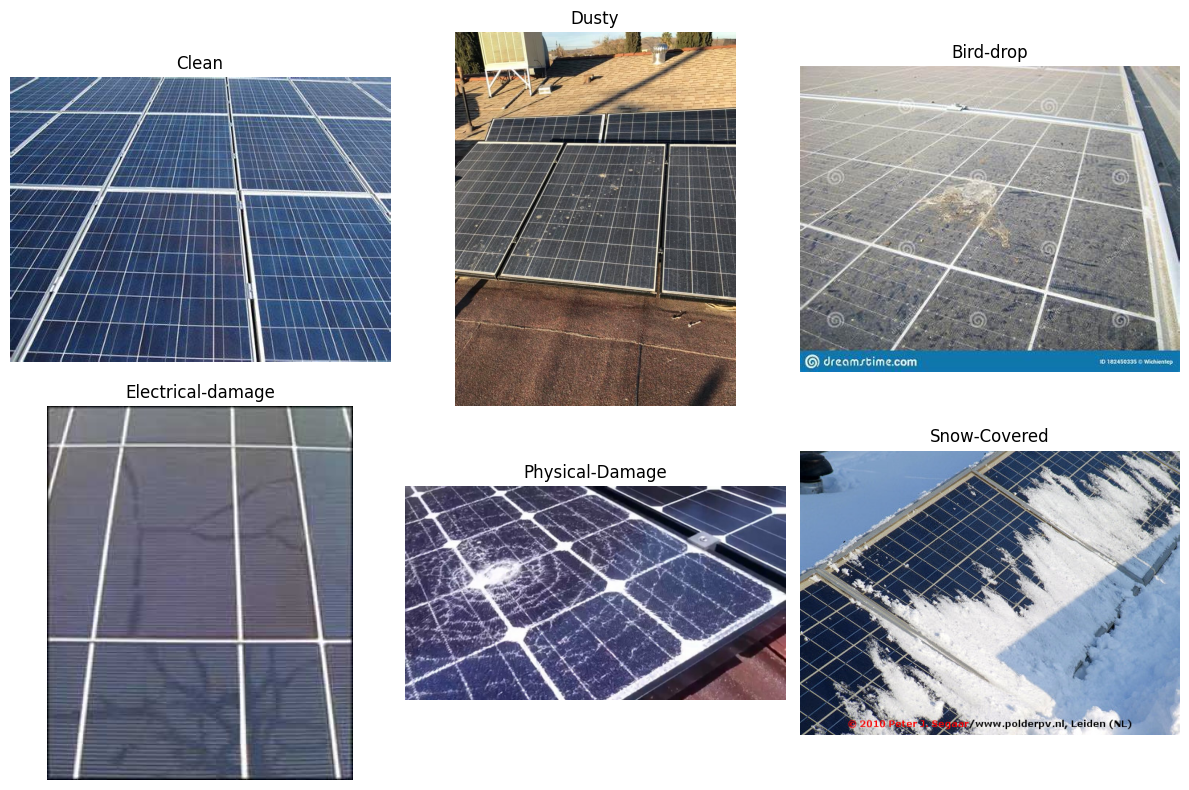

In [6]:

import os
import matplotlib.pyplot as plt
from PIL import Image

data_dir = os.path.join(dataset_path, "Faulty_solar_panel")

classes = [
    "Clean",
    "Dusty",
    "Bird-drop",
    "Electrical-damage",
    "Physical-Damage",
    "Snow-Covered"
]

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, class_name in zip(axes.flat, classes):
    folder = os.path.join(data_dir, class_name)

    image_files = []

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
                image_files.append(os.path.join(root, file))

    if image_files:
        with Image.open(image_files[0]) as img:
            ax.imshow(img.convert("RGB"))

    ax.set_title(class_name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [7]:

from PIL import Image
from collections import Counter
import os

image_sizes = Counter()
valid_images = 0
invalid_images = []

for root, dirs, files in os.walk(data_dir):
    for file in files:
        file_path = os.path.join(root, file)

        if file.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            try:
                with Image.open(file_path) as img:
                    img.verify()

                with Image.open(file_path) as img:
                    image_sizes[img.size] += 1

                valid_images += 1

            except Exception:
                invalid_images.append(file_path)

print("Valid images:", valid_images)
print("Invalid images:", len(invalid_images))
print("\nMost common image dimensions:")

for size, count in image_sizes.most_common(10):
    print(size, ":", count, "images")

Valid images: 885
Invalid images: 0

Most common image dimensions:
(720, 960) : 58 images
(2048, 1152) : 23 images
(2048, 1536) : 22 images
(474, 355) : 22 images
(1536, 2048) : 22 images
(800, 600) : 18 images
(960, 720) : 18 images
(474, 632) : 15 images
(1024, 768) : 12 images
(800, 533) : 10 images


In [8]:

from collections import Counter
import os

class_counts = Counter()

for class_name in classes:
    folder = os.path.join(data_dir, class_name)

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith(
                (".jpg", ".jpeg", ".png", ".webp")
            ):
                class_counts[class_name] += 1

for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

print("Total images:", sum(class_counts.values()))

Clean: 193
Dusty: 190
Bird-drop: 207
Electrical-damage: 103
Physical-Damage: 69
Snow-Covered: 123
Total images: 885


In [9]:

import os
import hashlib
from collections import defaultdict

hashes = defaultdict(list)

for class_name in classes:
    folder = os.path.join(data_dir, class_name)

    for root, dirs, files in os.walk(folder):
        for file in files:
            if file.lower().endswith(
                (".jpg", ".jpeg", ".png", ".webp")
            ):
                path = os.path.join(root, file)

                with open(path, "rb") as f:
                    file_hash = hashlib.sha256(f.read()).hexdigest()

                hashes[file_hash].append(path)

duplicates = [
    paths for paths in hashes.values()
    if len(paths) > 1
]

print("Total images:", sum(len(v) for v in hashes.values()))
print("Duplicate groups:", len(duplicates))
print("Extra duplicate copies:",
      sum(len(group) - 1 for group in duplicates))

for group in duplicates[:5]:
    print("\nDuplicate group:")
    for path in group:
        print(path)

Total images: 885
Duplicate groups: 74
Extra duplicate copies: 91

Duplicate group:
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (87).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (90).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (19).jpg

Duplicate group:
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (173).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (178).jpg

Duplicate group:
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (188).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (132).jpg

Duplicate group:
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (183).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (30).jpg

Duplicate group:
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (153).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Clean/Clean (157).jpg


In [10]:

from collections import Counter

cross_class_duplicates = []

for group in duplicates:
    labels = set()

    for path in group:
        relative_path = os.path.relpath(path, data_dir)
        class_name = relative_path.split(os.sep)[0]
        labels.add(class_name)

    if len(labels) > 1:
        cross_class_duplicates.append(group)

print("Duplicate groups across different classes:",
      len(cross_class_duplicates))

for group in cross_class_duplicates[:10]:
    print("\nConflicting duplicate group:")
    for path in group:
        print(path)


Duplicate groups across different classes: 2

Conflicting duplicate group:
/kaggle/input/solar-panel-images/Faulty_solar_panel/Dusty/Dust (187).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (193).jpg

Conflicting duplicate group:
/kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (184).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (46).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (57).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (22).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Bird-drop/Bird (176).jpg
/kaggle/input/solar-panel-images/Faulty_solar_panel/Physical-Damage/Physical (51).jpg


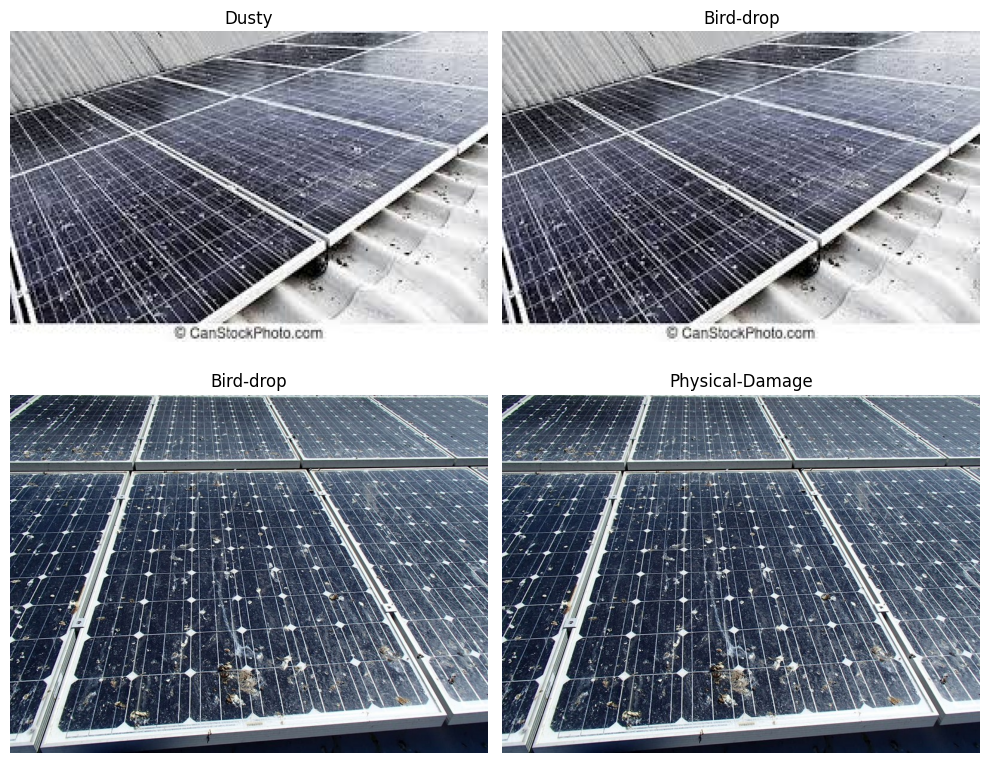

In [11]:

import matplotlib.pyplot as plt
from PIL import Image
import os

fig, axes = plt.subplots(
    len(cross_class_duplicates), 2,
    figsize=(10, 8)
)

for i, group in enumerate(cross_class_duplicates):
    selected = []
    seen_labels = set()

    for path in group:
        label = os.path.relpath(path, data_dir).split(os.sep)[0]

        if label not in seen_labels:
            selected.append((path, label))
            seen_labels.add(label)

    for j, (path, label) in enumerate(selected[:2]):
        with Image.open(path) as img:
            axes[i, j].imshow(img.convert("RGB"))

        axes[i, j].set_title(label)
        axes[i, j].axis("off")

plt.tight_layout()
plt.show()


In [12]:

cleaned_images = []
excluded_hashes = set()

# Identify hashes with conflicting labels
for group in cross_class_duplicates:
    with open(group[0], "rb") as f:
        excluded_hashes.add(
            hashlib.sha256(f.read()).hexdigest()
        )

# Keep one image per unique hash
for file_hash, paths in hashes.items():

    if file_hash in excluded_hashes:
        continue

    image_path = paths[0]

    class_name = os.path.relpath(
        image_path, data_dir
    ).split(os.sep)[0]

    cleaned_images.append((image_path, class_name))

print("Original images:", 885)
print("Unique images before conflict removal:", len(hashes))
print("Conflicting groups removed:", len(excluded_hashes))
print("Cleaned dataset images:", len(cleaned_images))


Original images: 885
Unique images before conflict removal: 794
Conflicting groups removed: 2
Cleaned dataset images: 792


In [13]:

from sklearn.model_selection import train_test_split

# Separate image paths and class labels
image_paths = [item[0] for item in cleaned_images]
labels = [item[1] for item in cleaned_images]

# First split: 70% training, 30% remaining
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=42,
    stratify=labels
)

# Second split: remaining 30% into validation and test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=42,
    stratify=temp_labels
)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

print("Total:", len(train_paths) + len(val_paths) + len(test_paths))


Training images: 554
Validation images: 119
Testing images: 119
Total: 792


In [14]:

import pandas as pd
from collections import Counter

train_counts = Counter(train_labels)
val_counts = Counter(val_labels)
test_counts = Counter(test_labels)

distribution = pd.DataFrame({
    "Training": [train_counts[c] for c in classes],
    "Validation": [val_counts[c] for c in classes],
    "Testing": [test_counts[c] for c in classes]
}, index=classes)

distribution["Total"] = distribution.sum(axis=1)

print(distribution)
print("\nTotal per split:")
print(distribution.sum(axis=0))


                   Training  Validation  Testing  Total
Clean                   130          28       28    186
Dusty                   127          28       27    182
Bird-drop               110          23       24    157
Electrical-damage        64          13       14     91
Physical-Damage          44          10        9     63
Snow-Covered             79          17       17    113

Total per split:
Training      554
Validation    119
Testing       119
Total         792
dtype: int64


In [15]:

import tensorflow as tf

IMG_SIZE = (224, 224)

def preprocess_image(image_path, label):

    # Read the image
    image = tf.io.read_file(image_path)

    # Decode image into 3 RGB channels
    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    # Resize while maintaining aspect ratio
    image = tf.image.resize_with_pad(
        image,
        IMG_SIZE[0],
        IMG_SIZE[1]
    )

    # Normalize pixel values to 0–1
    image = tf.cast(image, tf.float32) / 255.0

    return image, label

print("Image preprocessing function created successfully!")


Image preprocessing function created successfully!


In [16]:

BATCH_SIZE = 32

# Convert class names into numerical labels
class_to_index = {
    class_name: i
    for i, class_name in enumerate(classes)
}

def create_dataset(paths, labels, training=False):

    numeric_labels = [
        class_to_index[label] for label in labels
    ]

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, numeric_labels)
    )

    # Shuffle training data only
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=42
        )

    # Apply preprocessing
    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Group images into batches
    dataset = dataset.batch(BATCH_SIZE)

    # Improve data loading performance
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

train_ds = create_dataset(
    train_paths, train_labels, training=True
)

val_ds = create_dataset(
    val_paths, val_labels
)

test_ds = create_dataset(
    test_paths, test_labels
)

print("Training dataset created!")
print("Validation dataset created!")
print("Testing dataset created!")
print("Number of classes:", len(classes))


Training dataset created!
Validation dataset created!
Testing dataset created!
Number of classes: 6


In [17]:

# Take one batch from the training dataset
for images, labels in train_ds.take(1):

    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

    print("Minimum pixel value:",
          tf.reduce_min(images).numpy())

    print("Maximum pixel value:",
          tf.reduce_max(images).numpy())

    print("Sample labels:", labels.numpy())


Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Sample labels: [5 0 4 5 4 2 2 2 0 5 1 2 3 5 3 1 1 1 0 2 1 1 2 1 1 0 0 0 1 0 0 1]


In [18]:

from tensorflow import keras
from tensorflow.keras import layers

tf.keras.utils.set_random_seed(42)

baseline_model = keras.Sequential([
    layers.Input(shape=(224, 224, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),

    layers.Dense(6, activation="softmax")
])

baseline_model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:

baseline_model.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline CNN compiled successfully!")


Baseline CNN compiled successfully!


In [20]:

# Train the baseline CNN

EPOCHS = 15

baseline_history = baseline_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

print("Baseline CNN training completed!")


Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 85s 4s/step - accuracy: 0.2653 - loss: 1.7432 - val_accuracy: 0.2353 - val_loss: 1.7565
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 78s 4s/step - accuracy: 0.3051 - loss: 1.6838 - val_accuracy: 0.3445 - val_loss: 1.6519
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 74s 4s/step - accuracy: 0.3664 - loss: 1.6027 - val_accuracy: 0.3782 - val_loss: 1.5657
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 84s 4s/step - accuracy: 0.3845 - loss: 1.5325 - val_accuracy: 0.4370 - val_loss: 1.5064
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 72s 4s/step - accuracy: 0.3935 - loss: 1.4984 - val_accuracy: 0.4958 - val_loss: 1.4747
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 88s 4s/step - accuracy: 0.4043 - loss: 1.4629 - val_accuracy: 0.4118 - val_loss: 1.4693
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 83s 4s/step - accuracy: 0.3953 - loss: 1.4801 - val_accuracy: 0.3697 - val_loss: 1.5153
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 74s 4s/step - accuracy: 0.3881 - loss: 1.4746 - val_accuracy: 0.4202 - val_loss:

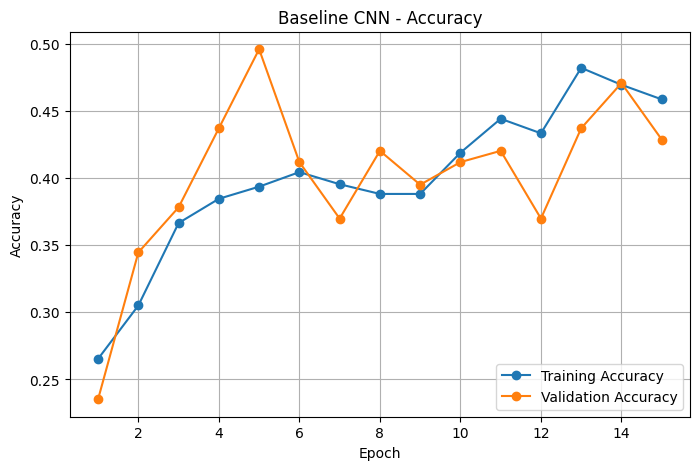

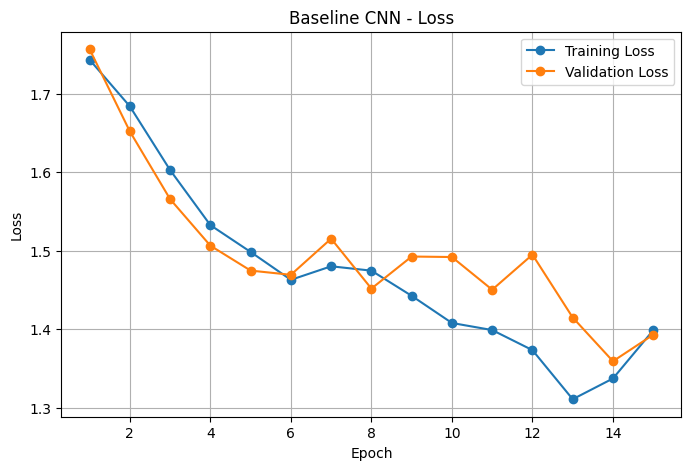

In [21]:

import matplotlib.pyplot as plt

history = baseline_history.history

epochs = range(1, len(history["accuracy"]) + 1)

# Plot accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    epochs,
    history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Baseline CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Plot loss
plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    epochs,
    history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Baseline CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [23]:

import os
import json

# Create a folder for our results
os.makedirs("/content/solar_panel_results", exist_ok=True)

# Save the trained baseline model
baseline_model.save(
    "/content/solar_panel_results/baseline_cnn.keras"
)

# Save training history
with open(
    "/content/solar_panel_results/baseline_history.json",
    "w"
) as f:
    json.dump(baseline_history.history, f)

print("Baseline CNN model saved successfully!")
print("Training history saved successfully!")


Baseline CNN model saved successfully!
Training history saved successfully!


In [25]:

from google.colab import files

# Download trained baseline CNN model
files.download(
    "/content/solar_panel_results/baseline_cnn.keras"
)

# Download training history
files.download(
    "/content/solar_panel_results/baseline_history.json"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [26]:
import tensorflow as tf
from tensorflow.keras import layers

# Step 9.2 - Create data augmentation layers
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1)
], name="data_augmentation")

print("Data augmentation layers created successfully!")

Data augmentation layers created successfully!


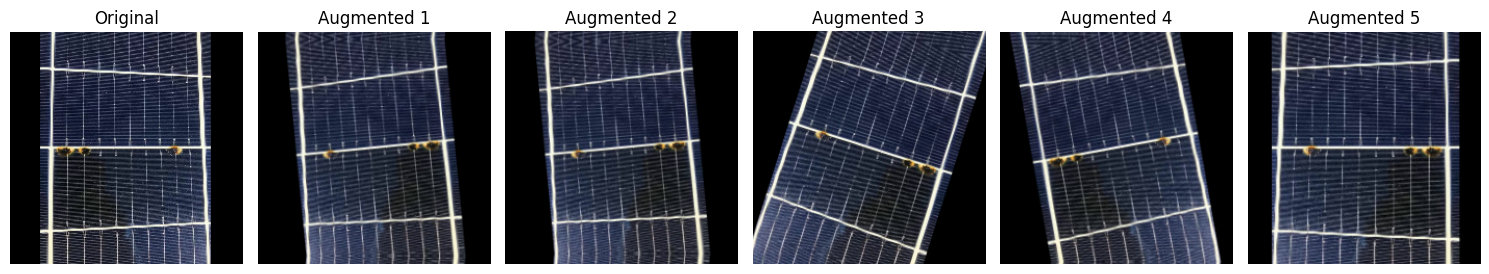

In [33]:

import matplotlib.pyplot as plt

# Take one batch from our training dataset
for images, labels in train_ds.take(1):
    sample_image = images[0]
    break

# Display the original image and 5 augmented versions
plt.figure(figsize=(15, 3))

plt.subplot(1, 6, 1)
plt.imshow(sample_image.numpy())
plt.title("Original")
plt.axis("off")

for i in range(5):
    augmented_image = data_augmentation(
        tf.expand_dims(sample_image, axis=0),
        training=True
    )

    plt.subplot(1, 6, i + 2)
    plt.imshow(
        tf.clip_by_value(augmented_image[0], 0, 1).numpy()
    )
    plt.title(f"Augmented {i+1}")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [34]:
import tensorflow as tf
from tensorflow.keras import layers, models

# Create a new CNN with data augmentation
augmented_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Apply augmentation during training
    data_augmentation,

    # Same CNN architecture as baseline
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),
    layers.Dense(6, activation="softmax")
])

# Display the architecture
augmented_model.summary()

print("Augmented CNN model created successfully!")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 6)              │           390 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,894 (398.02 KB)

 Trainable params: 101,894 (398.02 KB)

 Non-trainable params: 0 (0.00 B)

Augmented CNN model created successfully!


In [35]:
# Step 9.5 - Compile the augmented CNN

augmented_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Augmented CNN compiled successfully!")

Augmented CNN compiled successfully!


In [36]:
# Step 9.6 - Train the augmented CNN

augmented_history = augmented_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

print("Augmented CNN training completed!")

Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 83s 4s/step - accuracy: 0.2455 - loss: 1.7435 - val_accuracy: 0.2353 - val_loss: 1.7159
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 79s 4s/step - accuracy: 0.2978 - loss: 1.7022 - val_accuracy: 0.4034 - val_loss: 1.6479
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 83s 4s/step - accuracy: 0.3592 - loss: 1.6321 - val_accuracy: 0.3950 - val_loss: 1.5832
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 86s 5s/step - accuracy: 0.3466 - loss: 1.5884 - val_accuracy: 0.3277 - val_loss: 1.6415
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 77s 4s/step - accuracy: 0.3755 - loss: 1.5683 - val_accuracy: 0.4202 - val_loss: 1.4763
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 83s 5s/step - accuracy: 0.3845 - loss: 1.5437 - val_accuracy: 0.4286 - val_loss: 1.4659
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 76s 4s/step - accuracy: 0.3917 - loss: 1.5094 - val_accuracy: 0.2773 - val_loss: 1.8929
Epoch 8/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 78s 4s/step - accuracy: 0.3809 - loss: 1.5384 - val_accuracy: 0.3697 - val_loss:

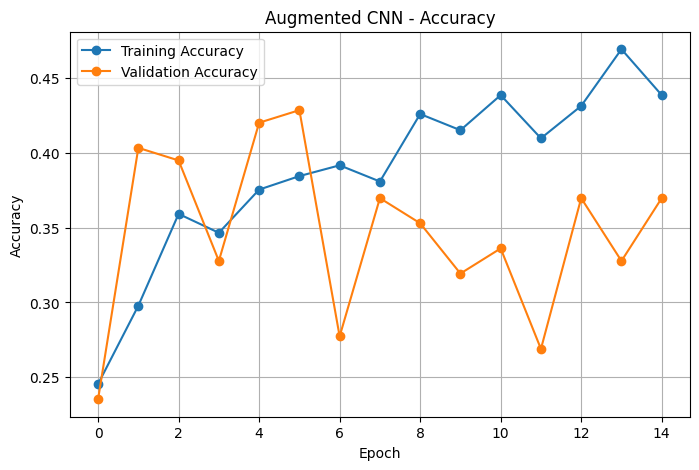

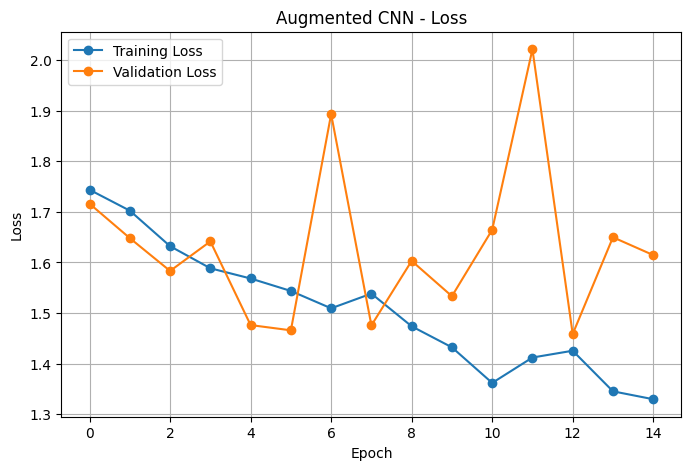

In [37]:

import matplotlib.pyplot as plt

# Step 9.7 - Plot augmented CNN results

# Accuracy graph
plt.figure(figsize=(8, 5))

plt.plot(
    augmented_history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    augmented_history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Augmented CNN - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Loss graph
plt.figure(figsize=(8, 5))

plt.plot(
    augmented_history.history["loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    augmented_history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Augmented CNN - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


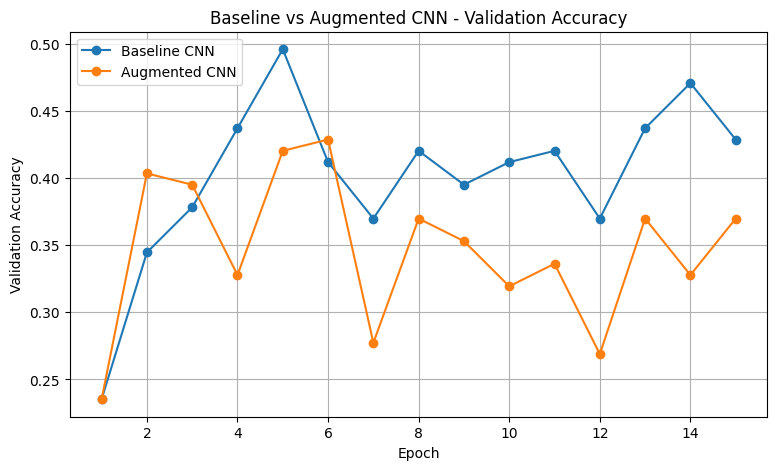

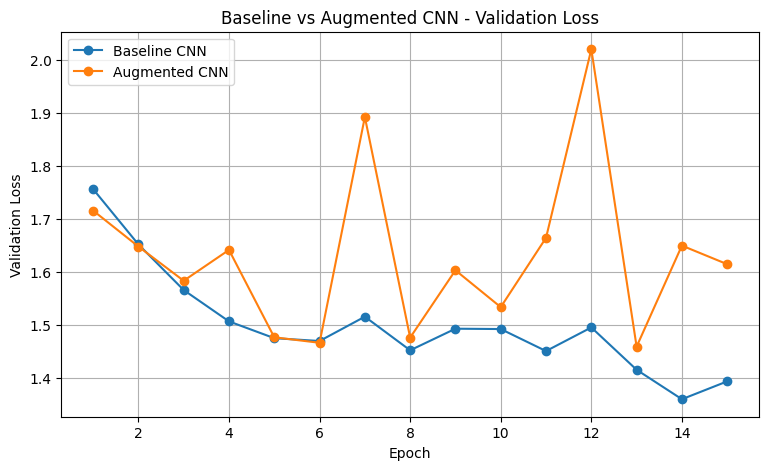

In [39]:

import matplotlib.pyplot as plt

# Step 9.8 - Compare baseline and augmented CNN

epochs = range(1, 16)

plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    baseline_history.history["val_accuracy"],
    label="Baseline CNN",
    marker="o"
)

plt.plot(
    epochs,
    augmented_history.history["val_accuracy"],
    label="Augmented CNN",
    marker="o"
)

plt.title("Baseline vs Augmented CNN - Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.legend()
plt.grid(True)
plt.show()

# Compare validation loss
plt.figure(figsize=(9, 5))

plt.plot(
    epochs,
    baseline_history.history["val_loss"],
    label="Baseline CNN",
    marker="o"
)

plt.plot(
    epochs,
    augmented_history.history["val_loss"],
    label="Augmented CNN",
    marker="o"
)

plt.title("Baseline vs Augmented CNN - Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [40]:

import os
import json

# Create results folder if it doesn't exist
os.makedirs("/content/solar_panel_results", exist_ok=True)

# Save augmented CNN model
augmented_model.save(
    "/content/solar_panel_results/augmented_cnn.keras"
)

# Save augmented CNN training history
with open(
    "/content/solar_panel_results/augmented_history.json",
    "w"
) as f:
    json.dump(augmented_history.history, f)

print("Augmented CNN model saved successfully!")
print("Augmented CNN training history saved successfully!")


Augmented CNN model saved successfully!
Augmented CNN training history saved successfully!


In [41]:

from google.colab import files

# Download the trained Augmented CNN model
files.download(
    "/content/solar_panel_results/augmented_cnn.keras"
)

# Download the training history
files.download(
    "/content/solar_panel_results/augmented_history.json"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>